In [1]:
import xarray as xr
from datetime import datetime, date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
ds = xr.load_dataset("target_variables/grib_files/tp_40_45.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly1 = var_hourly[:,:,:-7]

In [3]:
ds = xr.load_dataset("target_variables/grib_files/tp_46_51.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly2 = var_hourly[:,:,5:-7]

In [4]:
ds = xr.load_dataset("target_variables/grib_files/tp_52_57.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly3 = var_hourly[:,:,5:-7]

In [5]:
ds = xr.load_dataset("target_variables/grib_files/tp_58_63.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly4 = var_hourly[:,:,5:-7]

In [6]:
ds = xr.load_dataset("target_variables/grib_files/tp_64_69.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly5 = var_hourly[:,:,5:-7]

In [7]:
ds = xr.load_dataset("target_variables/grib_files/tp_70_75.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly6 = var_hourly[:,:,5:-7]

In [8]:
ds = xr.load_dataset("target_variables/grib_files/tp_76_81.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly7 = var_hourly[:,:,5:-7]

In [9]:
ds = xr.load_dataset("target_variables/grib_files/tp_82_87.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly8 = var_hourly[:,:,5:-7]

In [10]:
ds = xr.load_dataset("target_variables/grib_files/tp_88_93.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly9 = var_hourly[:,:,5:-7]

In [11]:
ds = xr.load_dataset("target_variables/grib_files/tp_94_99.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly10 = var_hourly[:,:,5:-7]

In [12]:
ds = xr.load_dataset("target_variables/grib_files/tp_00_05.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly11 = var_hourly[:,:,5:-7]

In [13]:
ds = xr.load_dataset("target_variables/grib_files/tp_06_10.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly12 = var_hourly[:,:,5:-7]

In [14]:
ds = xr.load_dataset("target_variables/grib_files/tp_11_15.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly13 = var_hourly[:,:,5:-7]

In [15]:
ds = xr.load_dataset("target_variables/grib_files/tp_16_20.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly14 = var_hourly[:,:,5:-7]

In [16]:
ds = xr.load_dataset("target_variables/grib_files/tp_21_25.grib", engine="cfgrib")
var_hourly = ds.tp.stack(hour=("time", "step")).swap_dims({"hour": "valid_time"})
var_hourly15 = var_hourly[:,:,5:]

In [17]:
var_hourly = xr.concat([var_hourly1, var_hourly2, var_hourly3, var_hourly4, var_hourly5, var_hourly6, var_hourly7, var_hourly8, var_hourly9, 
                        var_hourly10, var_hourly11, var_hourly12, var_hourly13, var_hourly14, var_hourly15], dim='valid_time')

In [18]:
var_hourly = var_hourly.reset_coords(['time', 'step', 'hour', 'number', 'surface'], drop=True)

In [19]:
var_daily = var_hourly.groupby(var_hourly.valid_time.dt.date).sum()

In [20]:
dates = var_daily.date.data
datetimes = np.zeros_like(dates)
for i in range(len(dates)):
    datetimes[i] = datetime.combine(dates[i], datetime.min.time())

In [21]:
var_daily.coords["time"] = ("date", datetimes)
var_daily = var_daily.swap_dims({"date": "time"})
var_daily = var_daily.reset_coords('date', drop=True)

In [22]:
month = var_daily.time.dt.month
day = var_daily.time.dt.day
var_daily = var_daily.sel(time=(month==12)|(month==1)|((month==2) & (day<29)))

In [23]:
var_daily = var_daily.sel(time=slice("1950-07", "2010-06"))

In [24]:
var_daily.to_netcdf('precip_daily.nc')

In [5]:
var_daily = xr.open_dataset('precip_daily.nc').tp

### Spatial weights

In [9]:
ds_oro = xr.load_dataset("target_variables/grib_files/orography_original_res.grib", engine="cfgrib")

Ignoring index file 'target_variables/grib_files/orography_original_res.grib.5b7b6.idx' incompatible with GRIB file


In [10]:
g = 9.80665

In [11]:
ds_oro = ds_oro.reset_coords(['number', 'time', 'step', 'surface', 'valid_time'], drop=True)

In [12]:
lat = ds_oro.latitude
land_frac = ds_oro.lsm + ds_oro.cl
mount_filt = xr.where(ds_oro.z/g < 1000, 1, 0)

In [13]:
weights = np.cos(np.deg2rad(lat))*land_frac*mount_filt
weights.name = "weights"

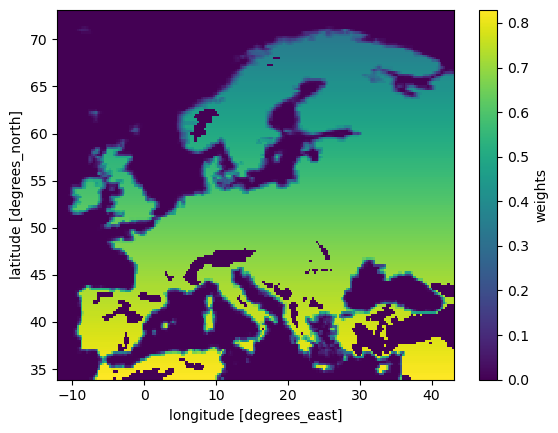

In [14]:
weights.plot()

In [15]:
var_7dMean = var_daily.rolling(time=7, min_periods=7, center=True).mean()
month = var_7dMean.time.dt.month
day = var_7dMean.time.dt.day
var_7dMean = var_7dMean.sel(time=~( ((month==12)&(day<4)) | ((month==2)&(day>25)) ))

**Northern Europe**: 4°E-42°E, 59°N-72°N  
**Western-Central Europe**: 11°W-19°E, 47°N-59°N  
**Eastern Europe**: 19°E-42°E, 47°N-59°N  
**Southwestern Europe**: 10°W-10°E, 36°N-47°N  
**Southeastern Europe**: 10°E-30°E, 35°N-47°N

In [17]:
import cartopy.crs as ccrs

In [18]:
precip_map = var_daily.mean('time')

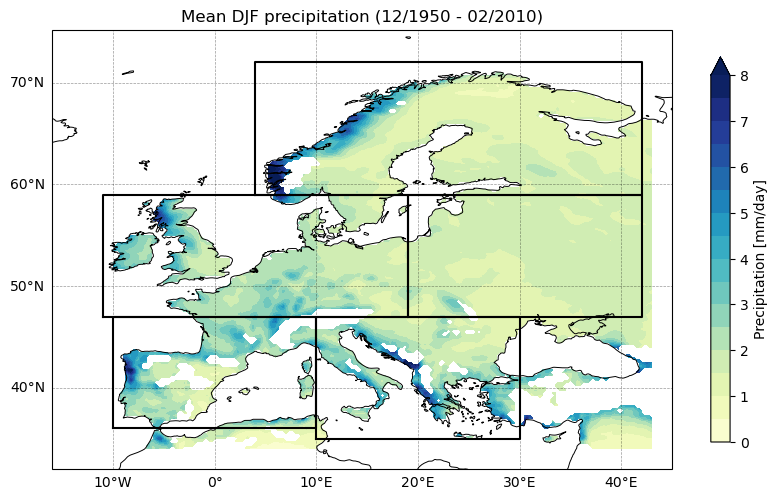

In [19]:
fig = plt.figure(figsize=(10,10))
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent((-16, 45, 32, 73))
ax.coastlines(resolution='50m', linewidth=0.7)
gl = ax.gridlines(draw_labels=True, linewidth=0.5, alpha=0.4, color='k', linestyle='--')
gl.right_labels = False
gl.top_labels = False
contf = ax.contourf(precip_map.longitude, precip_map.latitude, precip_map.where(land_frac*mount_filt>0.5)*1000, levels=np.linspace(0,8,17), cmap="YlGnBu", extend="max")
ax.plot([4,42,42,4,4], [59,59,72,72,59], 'k')
ax.plot([-11,19,19,-11,-11], [47,47,59,59,47], 'k')
ax.plot([19,42,42,19,19], [47,47,59,59,47], 'k')
ax.plot([-10,10,10,-10,-10], [36,36,47,47,36], 'k')
ax.plot([10,30,30,10,10], [35,35,47,47,35], 'k')
cbar = fig.colorbar(contf, shrink=0.5)
cbar.set_label('Precipitation [mm/day]')
ax.set_title('Mean DJF precipitation (12/1950 - 02/2010)')
plt.savefig('region_definition_precipitation.png', bbox_inches='tight')

In [20]:
regmean_NE = var_7dMean.sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_WCE = var_7dMean.sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_EE = var_7dMean.sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_SWE = var_7dMean.sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights).mean(dim=['longitude', 'latitude'])
regmean_SEE = var_7dMean.sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [21]:
print(np.corrcoef([regmean_NE, regmean_WCE, regmean_EE, regmean_SWE, regmean_SEE]))

[[ 1.          0.19523323  0.15231219 -0.28474688 -0.32754658]
 [ 0.19523323  1.          0.46362848  0.12385283  0.03589533]
 [ 0.15231219  0.46362848  1.          0.00333233  0.23897979]
 [-0.28474688  0.12385283  0.00333233  1.          0.34928074]
 [-0.32754658  0.03589533  0.23897979  0.34928074  1.        ]]


In [23]:
NE_corr = xr.corr(var_7dMean, regmean_NE, dim='time')
WCE_corr = xr.corr(var_7dMean, regmean_WCE, dim='time')
EE_corr = xr.corr(var_7dMean, regmean_EE, dim='time')
SWE_corr = xr.corr(var_7dMean, regmean_SWE, dim='time')
SEE_corr = xr.corr(var_7dMean, regmean_SEE, dim='time')

In [24]:
weights2 = weights*(var_7dMean.var(dim='time'))
weights2.name = "weights2"

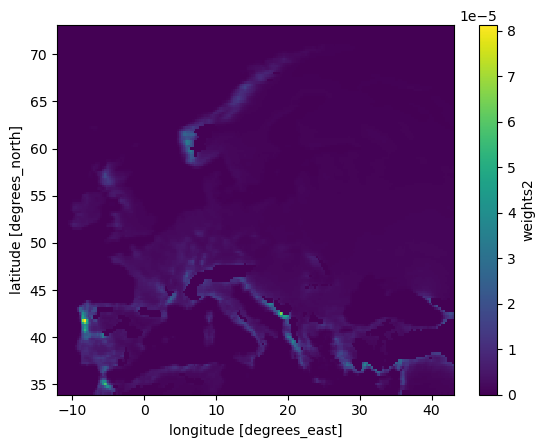

In [25]:
weights2.plot()

In [26]:
explvar_NE = (NE_corr**2).sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_WCE = (WCE_corr**2).sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_EE = (EE_corr**2).sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_SWE = (SWE_corr**2).sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights2).mean(dim=['longitude', 'latitude'])
explvar_SEE = (SEE_corr**2).sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights2).mean(dim=['longitude', 'latitude'])

In [27]:
print(explvar_NE.values)
print(explvar_WCE.values)
print(explvar_EE.values)
print(explvar_SWE.values)
print(explvar_SEE.values)

0.3399237441004785
0.4545991963201182
0.420038071831321
0.4403288928959006
0.3876094710413538


In [28]:
corrmean_NE = NE_corr.sel(longitude=slice(4,42), latitude=slice(72,59)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_WCE = WCE_corr.sel(longitude=slice(-11,19), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_EE = EE_corr.sel(longitude=slice(19,42), latitude=slice(59,47)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_SWE = SWE_corr.sel(longitude=slice(-10,10), latitude=slice(47,36)).weighted(weights).mean(dim=['longitude', 'latitude'])
corrmean_SEE = SEE_corr.sel(longitude=slice(10,30), latitude=slice(47,35)).weighted(weights).mean(dim=['longitude', 'latitude'])

In [29]:
print(corrmean_NE.values)
print(corrmean_WCE.values)
print(corrmean_EE.values)
print(corrmean_SWE.values)
print(corrmean_SEE.values)

0.5664700074837117
0.6617841221103823
0.6402162347269036
0.5689891595077662
0.5769895460765487


In [30]:
NE_corr.to_netcdf('precip_corr_NE.nc')
WCE_corr.to_netcdf('precip_corr_WCE.nc')
EE_corr.to_netcdf('precip_corr_EE.nc')
SWE_corr.to_netcdf('precip_corr_SWE.nc')
SEE_corr.to_netcdf('precip_corr_SEE.nc')